## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Dylan Wang

**Date:** 10/12/2026

In [2]:
# Q1.1:
# libs
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
from IPython.display import display

# the code from question 1
def createData(noise, N=50):
    np.random.seed(100)
    X1 = np.array([np.random.normal(1, noise, N),
                   np.random.normal(1, noise, N)])
    X2 = np.array([np.random.normal(3, noise, N),
                   np.random.normal(2, noise, N)])
    X3 = np.array([np.random.normal(5, noise, N),
                   np.random.normal(3, noise, N)])

    return pd.concat([
        pd.DataFrame({'x1': X1[0], 'x2': X1[1], 'group': 'a'}),
        pd.DataFrame({'x1': X2[0], 'x2': X2[1], 'group': 'b'}),
        pd.DataFrame({'x1': X3[0], 'x2': X3[1], 'group': 'c'})
    ])

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

datasets = {
    0.125: df0_125, 0.25: df0_25, 0.5: df0_5,
    1.0: df1_0, 2.0: df2_0
}
ks = range(1, 11)

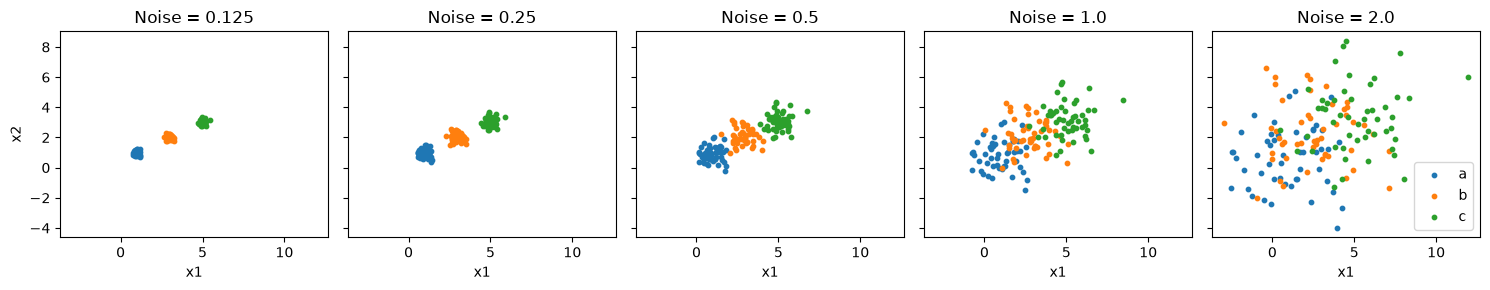

In [3]:
# Q1.2:
fig, axes = plt.subplots(1, 5, figsize=(15, 3), sharex=True, sharey=True)

for ax, (noise, df) in zip(axes, datasets.items()):
    for group, points in df.groupby('group'):
        ax.scatter(points['x1'], points['x2'], label=group, s=10)
    ax.set_title(f'Noise = {noise}')
    ax.set_xlabel('x1')

axes[0].set_ylabel('x2')
axes[-1].legend()
plt.tight_layout()
plt.show()

At noise 0.125 and 0.25, the three clusters are clearly separated.
As noise increases, the points spread out and overlap.
At noise 1 and 2, the groups become much harder to distinguish.

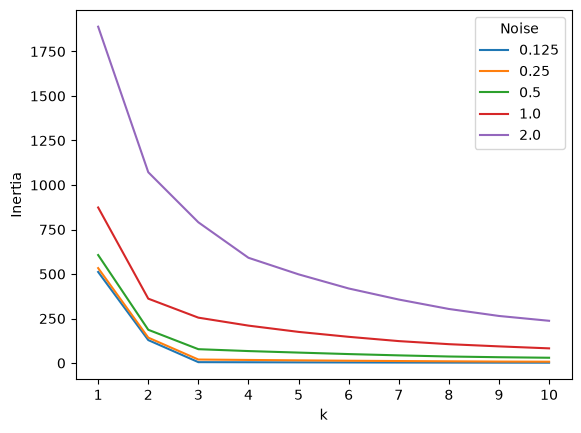

In [4]:
# Q1.3:
for noise, df in datasets.items():
    inertia = [
        KMeans(n_clusters=k, random_state=100, n_init=20)
        .fit(df[['x1', 'x2']]).inertia_
        for k in ks
    ]
    plt.plot(ks, inertia, label=str(noise))

plt.xlabel('k')
plt.ylabel('Inertia')
plt.xticks(ks)
plt.legend(title='Noise')
plt.show()

**Q1.3:** With low noise, the elbow is clear at k=3. Higher noise
increases inertia and makes the elbow less clear, so choosing k is harder.
All curves use the same vertical scale.

**Q1.4:** The elbow occurs when adding more clusters gives much smaller
improvements. Here, k=3 gives each low-noise group its own center.
Beyond that, extra clusters mostly split existing groups, so inertia
decreases only slightly.

In [6]:
# Q2.1:
df = pd.read_csv('data/SIPRI Military Expenditure Database.csv')
df = df[df['Year'] == 2020].dropna().copy()
df = df.drop(columns=['index'])
df['Country'] = df['Country'].str.strip()

features = [
    'Spending (2020 USD)',
    'Spending per Capita',
    'Percent of Government Spending',
    'Percent of GDP'
]

print('Countries:', len(df))
display(df[features].dtypes)
display(df.head())

Countries: 148


Spending (2020 USD)               float64
Spending per Capita               float64
Percent of Government Spending    float64
Percent of GDP                    float64
dtype: object

,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731


Dropping missing values leaves 148 countries. The four spending variables
are already numeric. I removed the extra index column and stripped
whitespace from country names. Only the four spending variables are
used for clustering.

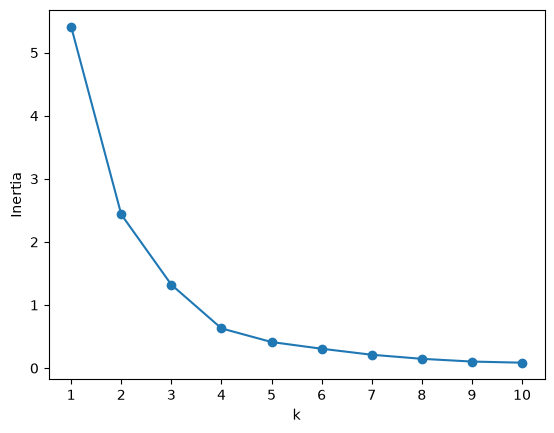

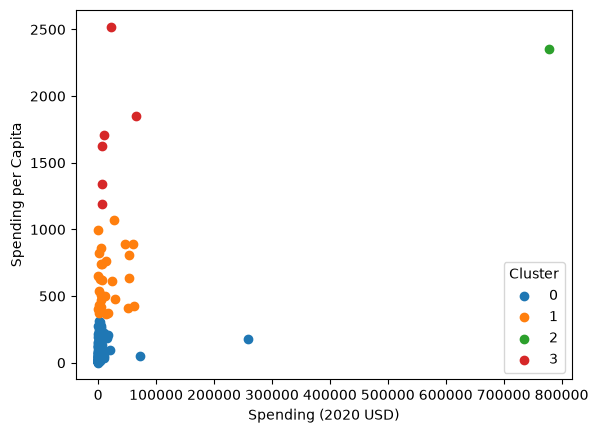

Spending (2020 USD)                                  \
                               count       mean       std        min   
spending_cluster                                                       
0                              111.0    4859.19  25405.74       8.62   
1                               30.0   17077.59  20583.05     405.79   
2                                1.0  778397.20       NaN  778397.20   
3                                6.0   19443.36  22861.51    6095.71   

                                                              \
                        25%        50%        75%        max   
spending_cluster                                               
0                    130.01     382.46    2297.03  257973.43   
1                   2294.04    5857.06   26296.00   61712.54   
2                 778397.20  778397.20  778397.20  778397.20   
3                   7023.25    8624.23   18857.07   64558.40   

                 Spending per Capita                                     \
                               count     mean     std      min      25%   
spending_cluster                                                          
0                              111.0    80.06   83.50     0.58    14.88   
1                               30.0   607.48  206.93   362.47   422.21   
2                                1.0  2351.63     NaN  2351.63  2351.63   
3                                6.0  1706.72  466.38  1193.60  1412.08   

                                             
                      50%      75%      max  
spending_cluster                             
0                   47.06   125.39   314.20  
1                  579.00   757.33  1070.62  
2                 2351.63  2351.63  2351.63  
3                 1665.45  1817.22  2520.40

,Country,spending_cluster,Spending (2020 USD),Spending per Capita
5540,United States of America,2,778397.2,2351.631858


In [7]:
# Q2.2 

# scree plot:
X = MinMaxScaler().fit_transform(df[features[:2]])

inertia = [
    KMeans(n_clusters=k, random_state=100, n_init=20).fit(X).inertia_
    for k in ks
]

plt.plot(ks, inertia, 'o-')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.xticks(ks)
plt.show()

# clustering and results:
df['spending_cluster'] = KMeans(
    n_clusters=4, random_state=100, n_init=20
).fit_predict(X)

for cluster, group in df.groupby('spending_cluster'):
    plt.scatter(group[features[0]], group[features[1]], label=str(cluster))

plt.xlabel(features[0])
plt.ylabel(features[1])
plt.legend(title='Cluster')
plt.show()

display(df.groupby('spending_cluster')[features[:2]].describe().round(2))
display(df.loc[df['Country'] == 'United States of America',
               ['Country', 'spending_cluster'] + features[:2]])

I chose k=4 because the scree plot flattens noticeably after 4.
The clusters contain 111, 30, 1, and 6 countries. They mainly separate
low, moderate, and high per-capita spending, plus the US.

The US is alone in cluster 2 because its total spending is much higher.
The other high-per-capita group includes Israel, Kuwait, Norway, Oman,
Saudi Arabia, and Singapore.

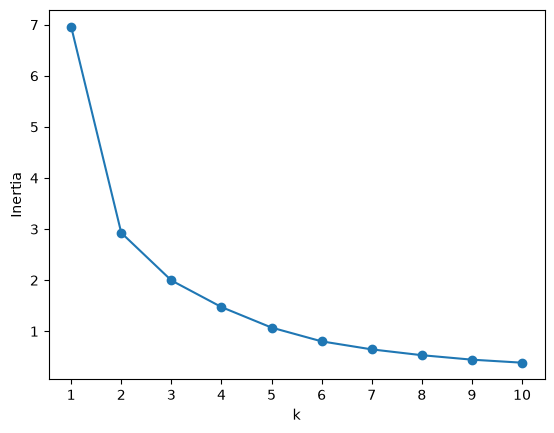

In [8]:
# Q2.3:

# scree plot:
X = MinMaxScaler().fit_transform(df[features[2:]])

inertia = [
    KMeans(n_clusters=k, random_state=100, n_init=20).fit(X).inertia_
    for k in ks
]

plt.plot(ks, inertia, 'o-')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.xticks(ks)
plt.show()

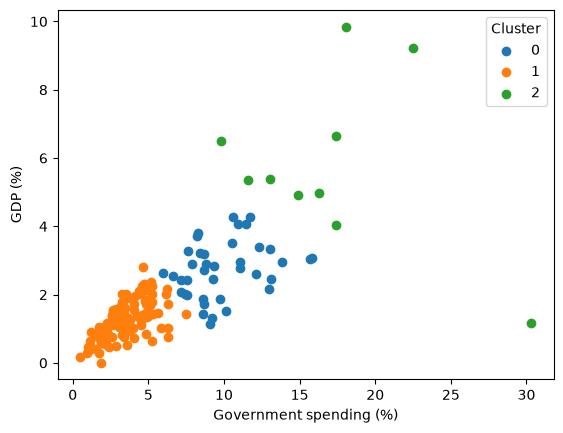

Percent of Government Spending                              \
                                        count   mean    std    min    25%   
burden_cluster                                                              
0                                        39.0  0.099  0.024  0.060  0.082   
1                                        99.0  0.036  0.015  0.005  0.026   
2                                        10.0  0.171  0.059  0.098  0.135   

                                    Percent of GDP                       \
                  50%    75%    max          count   mean    std    min   
burden_cluster                                                            
0               0.092  0.113  0.158           39.0  0.027  0.008  0.011   
1               0.034  0.047  0.075           99.0  0.013  0.006  0.000   
2               0.168  0.179  0.303           10.0  0.058  0.025  0.012   

                                            
                  25%    50%    75%    max  
burden_cluster                              
0               0.021  0.028  0.032  0.043  
1               0.008  0.013  0.017  0.028  
2               0.049  0.054  0.066  0.098

,Country,burden_cluster,Percent of Government Spending,Percent of GDP
5540,United States of America,0,0.081976,0.037179


In [9]:
# 2.3 clustering and results:
df['burden_cluster'] = KMeans(
    n_clusters=3, random_state=100, n_init=20
).fit_predict(X)

for cluster, group in df.groupby('burden_cluster'):
    plt.scatter(group[features[2]] * 100, group[features[3]] * 100,
                label=str(cluster))

plt.xlabel('Government spending (%)')
plt.ylabel('GDP (%)')
plt.legend(title='Cluster')
plt.show()

display(df.groupby('burden_cluster')[features[2:]].describe().round(3))
display(df.loc[df['Country'] == 'United States of America',
               ['Country', 'burden_cluster'] + features[2:]])

I chose k=3 for low, moderate, and high military spending burdens,
although the elbow is less clear and k=2 is also reasonable.
The clusters contain 39, 99, and 10 countries.

The US belongs to the moderate-burden group instead of standing alone.
Unlike part 2, these clusters reflect military spending relative to
government budgets and GDP. A high total spender does not necessarily
have the highest burden.

The percentage columns contain fractions, so the plot multiplies them
by 100. The describe table keeps the original values.

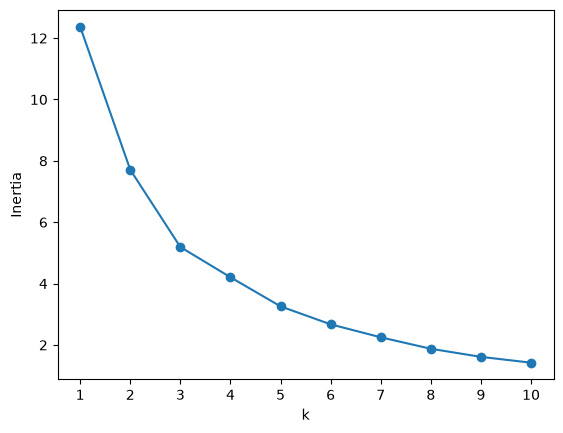

In [10]:
# Q2.4
# scree plot

X = MinMaxScaler().fit_transform(df[features])

inertia = [
    KMeans(n_clusters=k, random_state=100, n_init=20).fit(X).inertia_
    for k in ks
]

plt.plot(ks, inertia, 'o-')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.xticks(ks)
plt.show()

,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
all_cluster,,,,
0,7086.473,196.927,0.040,0.013
1,147964.582,1875.151,0.135,0.063
2,8786.087,212.689,0.123,0.033


all_cluster
0    111
1      6
2     31
dtype: int64
Countries in the US cluster:
['Israel', 'Kuwait', 'Oman', 'Saudi Arabia', 'Singapore', 'United States of America']


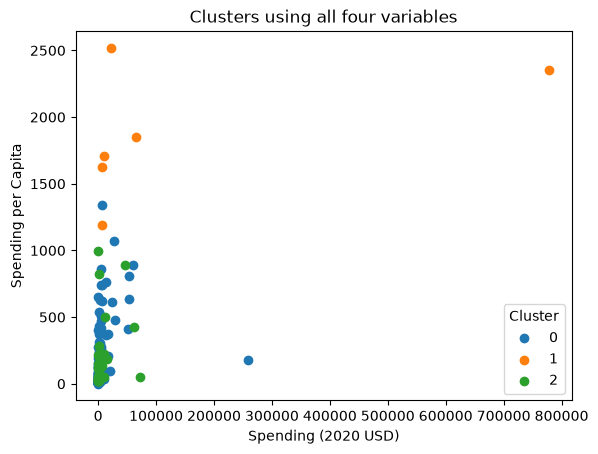

In [11]:
# 2.4 clustering and results:

df['all_cluster'] = KMeans(
    n_clusters=3, random_state=100, n_init=20
).fit_predict(X)

display(df.groupby('all_cluster')[features].mean().round(3))
print(df.groupby('all_cluster').size())

us_cluster = df.loc[
    df['Country'] == 'United States of America', 'all_cluster'
].iloc[0]

print('Countries in the US cluster:')
print(df.loc[df['all_cluster'] == us_cluster, 'Country'].tolist())

for cluster, group in df.groupby('all_cluster'):
    plt.scatter(group[features[0]], group[features[1]], label=str(cluster))

plt.xlabel(features[0])
plt.ylabel(features[1])
plt.title('Clusters using all four variables')
plt.legend(title='Cluster')
plt.show()

**Q2.4:** I chose k=3 as a reasonable grouping, though the elbow is not
sharp. The clusters contain 111, 6, and 31 countries. They broadly
separate lower spending and burden, high per-capita spending and/or
burden, and higher burden with more modest per-capita spending.

The US now groups with Israel, Kuwait, Oman, Saudi Arabia, and Singapore.
Using all four variables combines spending levels with relative burden,
so membership changes from the earlier models. The plot shows only
two of the four variables used.

**Q2.5:** Yes. K-means shows differences between total spending,
spending per person, and military budget burden. It highlights the
US as an extreme total spender, but not the country with the highest
relative burden. The results depend on the variables and k chosen.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 3a8f3c7a342e6e753cf643a45436da09fb5c5ae6
- **AI tool and model used:** GPT-6
- **Revision date:** October 12, 2026


### *Prompts used

1. “review my phase 1 code against the questions, check if my code correctly answers every question, and give suggestions and concrete modification plans"
2. "elaborate on those modification plans and be more specific"



### *AI-proposed changes


1. Preserve Phase 1: it covers every subquestion, runs successfully, and its reported counts and US memberships match fresh calculations. Make the Phase 2 solution independently runnable.
2. Add data-quality checks for numeric types, finite values, unique countries, and nonnegative spending; explain that percentage variables are fractions and must be multiplied by 100 for percentage displays.
3. Keep the common-scale Q1 scree plot and add curves divided by their k=1 inertia to compare curve shapes across noise levels; explain why high noise can hide the three generating groups.
4. Retain the defensible choices k=4, k=3, and k=3 for the three Q2 models, mark them on scree plots, and show numerical inertia reductions. Treat the elbow as a judgment rather than proof of a unique optimal k.
5. Provide cluster sizes, conditional describe tables, country memberships, US results, and cross-tabulations between Q2 models; show the four-variable labels in both two-dimensional feature views.
6. Explain the limitations of min-max scaling, outliers, arbitrary cluster labels, and descriptive interpretation; leave the required unaided reflection for the student.


### *Evaluation of AI suggestions



| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | All Phase 1 code ran successfully. Counts were 148 countries; cluster sizes were (111, 30, 1, 6), (39, 99, 10), and (111, 6, 31). Phase 1 source matches the cited commit and is preserved. |
| 2 | Accept | The CSV's four features are numeric; filtering 2020 and dropping missing rows yields 148 countries. Phase 2 checks finite values, duplicates, and nonnegative values. Percent columns are retained as fractions for fitting and converted only for displays. |
| 3 | Accept | Raw inertia compares absolute within-cluster variation. Dividing by k=1 inertia makes shape comparisons easier without changing the fitted models or the original common-scale plot. |
| 4 | Modify | Keep the original k choices because their results are interpretable. Add numerical reductions and plot markers, but do not claim that an elbow establishes a unique optimum. |
| 5 | Accept | Recomputed labels reproduce Phase 1 counts and US memberships. Cross-tabs quantify membership changes instead of relying only on descriptions; both projections use the same four-feature labels. |
| 6 | Accept | Min-max scaling does not remove skew or outlier influence. Cluster IDs have no ranking, and these clusters describe the chosen features rather than causes or policy quality. The reflection remains for the student to write without AI. |



### *AI-assisted solution in full

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
from IPython.display import display

SEED = 100
N_INIT = 20
K_VALUES = list(range(1, 11))

def fit_kmeans(X, k):
    return KMeans(n_clusters=k, random_state=SEED, n_init=N_INIT).fit(X)

def scree_values(X):
    return np.array([fit_kmeans(X, k).inertia_ for k in K_VALUES])

def plot_scree(X, title, chosen_k):
    inertia = scree_values(X)
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.plot(K_VALUES, inertia, 'o-')
    ax.axvline(chosen_k, linestyle='--', color='gray', label=f'Chosen k={chosen_k}')
    ax.set(xlabel='k', ylabel='Inertia (scaled features)', title=title, xticks=K_VALUES)
    ax.legend()
    plt.tight_layout()
    plt.show()
    reductions = np.r_[np.nan, 100 * (inertia[:-1] - inertia[1:]) / inertia[:-1]]
    display(pd.DataFrame({'k': K_VALUES, 'inertia': inertia,
                          'reduction from previous k (%)': reductions}).round(3))

def scatter_clusters(frame, columns, label_column, title, percentages=False):
    fig, ax = plt.subplots(figsize=(7, 4))
    multiplier = 100 if percentages else 1
    for label, group in frame.groupby(label_column):
        ax.scatter(group[columns[0]] * multiplier, group[columns[1]] * multiplier,
                   label=str(label), alpha=0.8, s=30)
    us = frame.loc[frame['Country'].eq('United States of America')]
    if len(us):
        ax.annotate('United States',
                    (us[columns[0]].iloc[0] * multiplier,
                     us[columns[1]].iloc[0] * multiplier),
                    xytext=(8, 8), textcoords='offset points')
    suffix = ' (%)' if percentages else ''
    ax.set(xlabel=columns[0] + suffix, ylabel=columns[1] + suffix, title=title)
    ax.legend(title='Cluster')
    plt.tight_layout()
    plt.show()

def report_clusters(frame, columns, label_column):
    print('Cluster sizes:')
    display(frame.groupby(label_column).size().rename('countries').to_frame())
    print('Conditional describe table (original data units):')
    display(frame.groupby(label_column)[columns].describe().round(3))
    print('United States:')
    display(frame.loc[frame['Country'].eq('United States of America'),
                      ['Country', label_column] + columns])
    print('Country membership:')
    display(frame.groupby(label_column)['Country'].agg(list).to_frame())


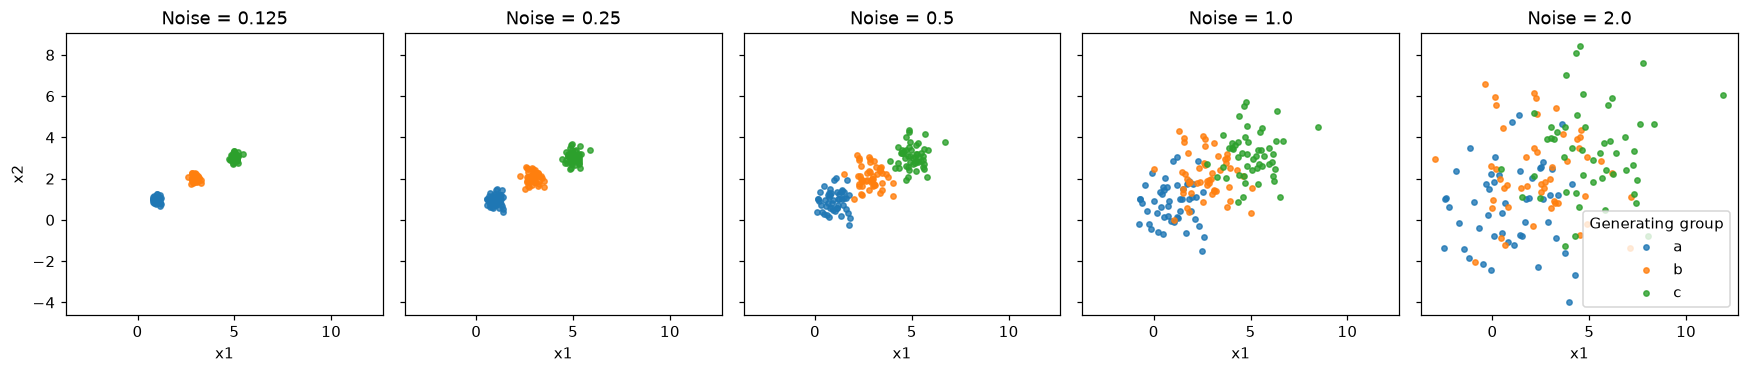

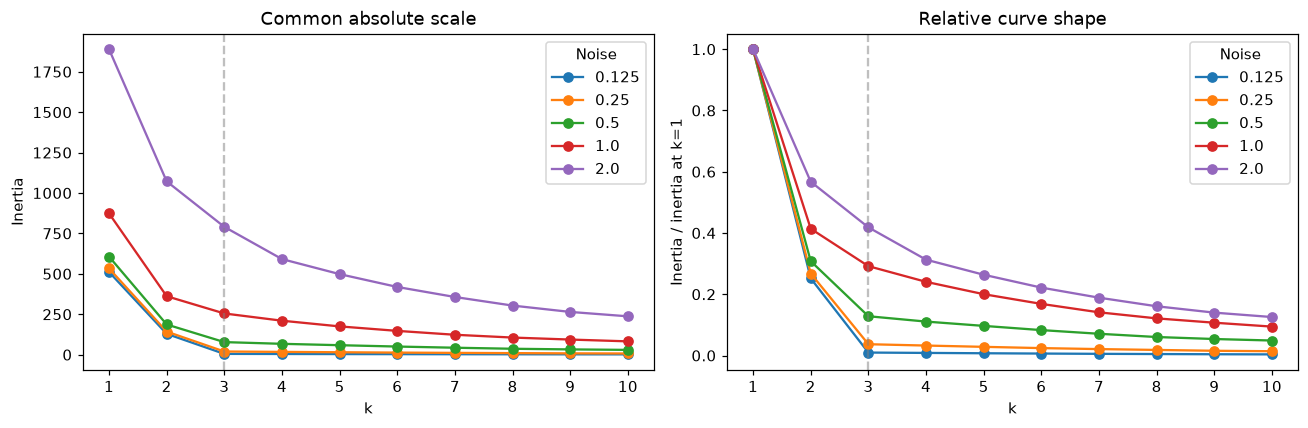

In [2]:
# Q1.1: reproduce the supplied simulation without changing the global RNG.
def create_data_phase2(noise, N=50):
    rng = np.random.RandomState(SEED)
    groups = []
    for group, center in zip('abc', [(1, 1), (3, 2), (5, 3)]):
        groups.append(pd.DataFrame({'x1': rng.normal(center[0], noise, N),
                                    'x2': rng.normal(center[1], noise, N),
                                    'group': group}))
    return pd.concat(groups, ignore_index=True)

noise_levels = [0.125, 0.25, 0.5, 1.0, 2.0]
simulations = {noise: create_data_phase2(noise) for noise in noise_levels}
df0_125_p2, df0_25_p2, df0_5_p2, df1_0_p2, df2_0_p2 = simulations.values()
assert all(frame.shape == (150, 3) for frame in simulations.values())

# Q1.2: common axes keep visual comparisons meaningful.
fig, axes = plt.subplots(1, 5, figsize=(16, 3.5), sharex=True, sharey=True)
for ax, (noise, frame) in zip(axes, simulations.items()):
    for group, points in frame.groupby('group'):
        ax.scatter(points['x1'], points['x2'], label=group, s=12, alpha=0.8)
    ax.set(title=f'Noise = {noise}', xlabel='x1')
axes[0].set_ylabel('x2')
axes[-1].legend(title='Generating group')
plt.tight_layout()
plt.show()

# Q1.3: show absolute variation and relative curve shape side by side.
simulation_inertias = {noise: scree_values(frame[['x1', 'x2']])
                      for noise, frame in simulations.items()}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for noise, inertia in simulation_inertias.items():
    axes[0].plot(K_VALUES, inertia, 'o-', label=str(noise))
    axes[1].plot(K_VALUES, inertia / inertia[0], 'o-', label=str(noise))
for ax in axes:
    ax.set_xlabel('k')
    ax.set_xticks(K_VALUES)
    ax.axvline(3, color='gray', linestyle='--', alpha=0.5)
    ax.legend(title='Noise')
axes[0].set(ylabel='Inertia', title='Common absolute scale')
axes[1].set(ylabel='Inertia / inertia at k=1', title='Relative curve shape')
plt.tight_layout()
plt.show()


**Q1.2:** At noise 0.125 and 0.25, the three generating groups are clearly separated. At 0.5, the groups spread toward one another. At 1.0 and especially 2.0, overlap makes the original groups difficult to distinguish.

**Q1.3:** Low-noise curves have a clear elbow near k=3. Higher noise increases residual within-cluster variation and makes the transition more gradual, so selecting k becomes less definitive. The left panel compares raw inertia on one scale; the right compares proportional reductions. The relative plot supplements the raw plot and does not alter clustering. Knowing that the simulation generated three groups does not guarantee that k=3 is visually recoverable at high noise.

**Q1.4:** Inertia is the sum of squared distances from points to their assigned centroids. With well-separated groups, increasing k from 1 toward 3 lets centroids represent distinct groups, producing large improvements. Beyond 3, additional centroids mainly subdivide the noise within those groups, so improvements become smaller. This change in slope is the elbow. When the groups overlap, the distinction between representing a new group and splitting an existing one becomes less sharp.


In [3]:
# Q2.1: filter, remove missing rows, and inspect data quality.
raw_p2 = pd.read_csv('data/SIPRI Military Expenditure Database.csv')
features_p2 = ['Spending (2020 USD)', 'Spending per Capita',
               'Percent of Government Spending', 'Percent of GDP']
year_2020 = raw_p2.loc[raw_p2['Year'].eq(2020)].copy()
military = year_2020.dropna().drop(columns=['index']).copy()
military['Country'] = military['Country'].str.strip()
assert len(military) == 148, 'Unexpected number of complete countries'
assert military['Country'].ne('').all()
assert military['Country'].is_unique, 'Duplicate country observations'
assert all(pd.api.types.is_numeric_dtype(military[c]) for c in features_p2)
assert np.isfinite(military[features_p2].to_numpy()).all()
assert military[features_p2].ge(0).all().all()
print(f'2020 rows: {len(year_2020)}; complete countries: {len(military)}; '
      f'rows removed: {len(year_2020) - len(military)}')
display(military[features_p2].dtypes.rename('dtype').to_frame())
display(military.head())

spending_features = features_p2[:2]
burden_features = features_p2[2:]
# Each model gets its own scaler fitted to its selected features.
spending_X = MinMaxScaler().fit_transform(military[spending_features])
burden_X = MinMaxScaler().fit_transform(military[burden_features])
all_X = MinMaxScaler().fit_transform(military[features_p2])


2020 rows: 173; complete countries: 148; rows removed: 25


,dtype
Spending (2020 USD),float64
Spending per Capita,float64
Percent of Government Spending,float64
Percent of GDP,float64


,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731


**Q2.1:** Filtering 2020 and dropping all rows with missing values leaves 148 countries. No further numeric parsing or imputation is needed in this file. The unused index column is removed and country whitespace is stripped. The checks confirm unique country rows, numeric finite feature values, and nonnegative spending. Year and country names are not clustering inputs. Both percentage variables store proportions: 0.03 means 3%. Multiplying them by 100 is useful for display but would give the same min-max normalized values.


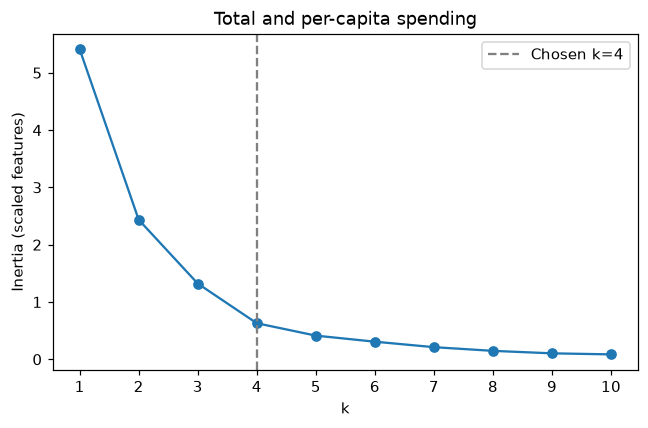

,k,inertia,reduction from previous k (%)
0,1,5.411,NaN
1,2,2.435,54.998
2,3,1.322,45.722
3,4,0.629,52.382
4,5,0.413,34.364
5,6,0.307,25.698
6,7,0.212,31.070
7,8,0.147,30.484
8,9,0.104,29.426
9,10,0.086,17.497


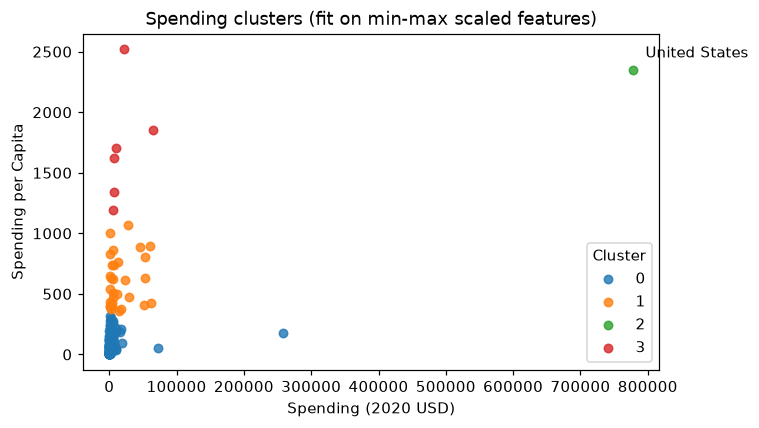

Cluster sizes:


,countries
spending_cluster,
0,111
1,30
2,1
3,6


Conditional describe table (original data units):


Spending (2020 USD)              ... Spending per Capita          
                               count        mean  ...                 75%       max
spending_cluster                                  ...                              
0                              111.0    4859.185  ...             125.388   314.201
1                               30.0   17077.591  ...             757.329  1070.623
2                                1.0  778397.200  ...            2351.632  2351.632
3                                6.0   19443.362  ...            1817.220  2520.399

[4 rows x 16 columns]

United States:


,Country,spending_cluster,Spending (2020 USD),Spending per Capita
5540,United States of America,2,778397.2,2351.631858


Country membership:


,Country
spending_cluster,
0,"[Afghanistan, Albania, Algeria, Angola, Argent..."
1,"[Australia, Austria, Bahrain, Belgium, Brunei,..."
2,[United States of America]
3,"[Israel, Kuwait, Norway, Oman, Saudi Arabia, S..."


In [4]:
# Q2.2: total and per-capita spending.
plot_scree(spending_X, 'Total and per-capita spending', chosen_k=4)
spending_model = fit_kmeans(spending_X, 4)
military['spending_cluster'] = spending_model.labels_
scatter_clusters(military, spending_features, 'spending_cluster',
                 'Spending clusters (fit on min-max scaled features)')
report_clusters(military, spending_features, 'spending_cluster')
assert military.groupby('spending_cluster').size().tolist() == [111, 30, 1, 6]
assert military.loc[military['Country'].eq('United States of America'),
                    'spending_cluster'].iloc[0] == 2


**Q2.2:** k=4 is a reasonable elbow choice because the curve has flattened substantially by this point; the numerical reductions show the remaining gains rather than establishing a unique optimum. The clusters contain 111, 30, 1, and 6 countries. Cluster 0 has low per-capita spending, cluster 1 has moderate per-capita spending, and cluster 3 contains high per-capita spenders Israel, Kuwait, Norway, Oman, Saudi Arabia, and Singapore. Cluster 2 contains only the United States, whose total expenditure is extreme relative to other countries. The original-unit scatterplot and describe table make these distinctions interpretable. Cluster numbers are arbitrary identifiers, not ranks.


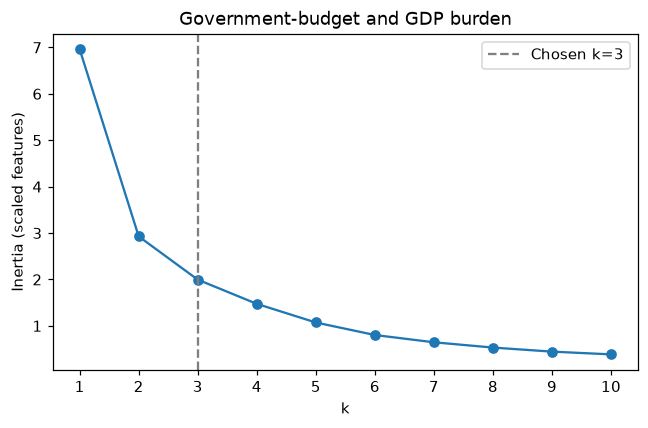

,k,inertia,reduction from previous k (%)
0,1,6.961,NaN
1,2,2.927,57.945
2,3,1.996,31.824
3,4,1.474,26.122
4,5,1.073,27.244
5,6,0.803,25.119
6,7,0.646,19.552
7,8,0.532,17.606
8,9,0.445,16.424
9,10,0.386,13.320


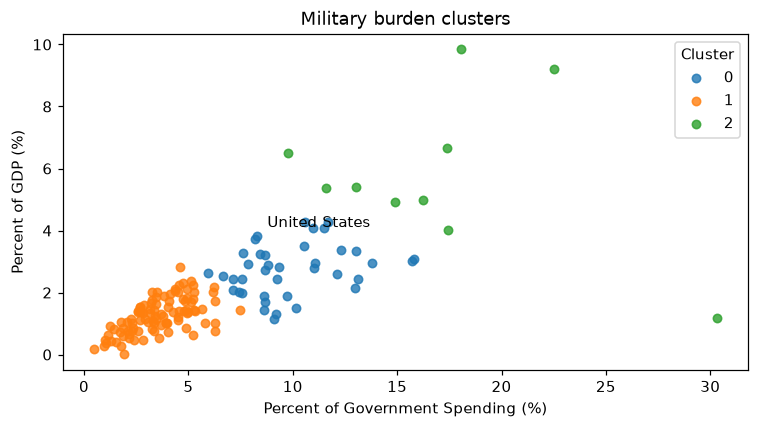

Cluster sizes:


,countries
burden_cluster,
0,39
1,99
2,10


Conditional describe table (original data units):


Percent of Government Spending         ... Percent of GDP       
                                        count   mean  ...            75%    max
burden_cluster                                        ...                      
0                                        39.0  0.099  ...          0.032  0.043
1                                        99.0  0.036  ...          0.017  0.028
2                                        10.0  0.171  ...          0.066  0.098

[3 rows x 16 columns]

United States:


...

,Country
burden_cluster,
0,"[Bahrain, Bangladesh, Botswana, Brunei, Burkin..."
1,"[Afghanistan, Albania, Angola, Argentina, Aust..."
2,"[Algeria, Armenia, Azerbaijan, Belarus, Israel..."


Mean burden in percent:


,Percent of Government Spending,Percent of GDP
burden_cluster,,
0,9.87,2.74
1,3.58,1.27
2,17.13,5.81


Spending versus burden membership:


burden_cluster,0,1,2
spending_cluster,,,
0,32,73,6
1,5,25,0
2,1,0,0
3,1,1,4


In [5]:
# Q2.3: relative military spending burden.
plot_scree(burden_X, 'Government-budget and GDP burden', chosen_k=3)
burden_model = fit_kmeans(burden_X, 3)
military['burden_cluster'] = burden_model.labels_
scatter_clusters(military, burden_features, 'burden_cluster',
                 'Military burden clusters', percentages=True)
report_clusters(military, burden_features, 'burden_cluster')
print('Mean burden in percent:')
display((military.groupby('burden_cluster')[burden_features].mean() * 100).round(2))
print('Spending versus burden membership:')
display(pd.crosstab(military['spending_cluster'], military['burden_cluster']))
assert military.groupby('burden_cluster').size().tolist() == [39, 99, 10]


**Q2.3:** k=3 gives an interpretable low/moderate/high burden grouping, although the elbow is gradual and k=2 is also defensible. Cluster 1 contains 99 low-burden countries, cluster 0 contains 39 moderate-burden countries, and cluster 2 contains 10 high-burden countries. The US joins cluster 0 rather than remaining alone. These features measure military expenditure relative to government budgets and GDP, so high absolute spending need not imply the greatest burden. The cross-tab shows how the spending-based groups split among burden groups. The scatterplot and mean table use percent; the conditional describe table uses the original fractions.


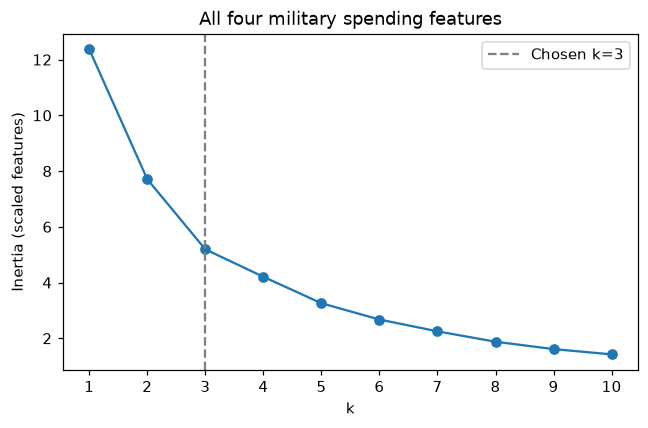

,k,inertia,reduction from previous k (%)
0,1,12.372,NaN
1,2,7.710,37.687
2,3,5.193,32.647
3,4,4.207,18.982
4,5,3.258,22.553
5,6,2.673,17.970
6,7,2.250,15.814
7,8,1.876,16.608
8,9,1.613,14.051
9,10,1.423,11.779


Cluster sizes:


,countries
all_cluster,
0,111
1,6
2,31


Conditional describe table (original data units):


Spending (2020 USD)                          ... Percent of GDP              
                          count        mean         std  ...            50%    75%    max
all_cluster                                              ...                             
0                         111.0    7086.473   26479.380  ...          0.014  0.018  0.028
1                           6.0  147964.582  309635.190  ...          0.059  0.085  0.098
2                          31.0    8786.087   17901.909  ...          0.032  0.041  0.067

[3 rows x 32 columns]

...

,Country,all_cluster,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
5540,United States of America,1,778397.2,2351.631858,0.081976,0.037179


Country membership:


,Country
all_cluster,
0,"[Afghanistan, Albania, Angola, Argentina, Aust..."
1,"[Israel, Kuwait, Oman, Saudi Arabia, Singapore..."
2,"[Algeria, Armenia, Azerbaijan, Bahrain, Belaru..."


Cluster means in original units:


,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
all_cluster,,,,
0,7086.473,196.927,0.040,0.013
1,147964.582,1875.151,0.135,0.063
2,8786.087,212.689,0.123,0.033


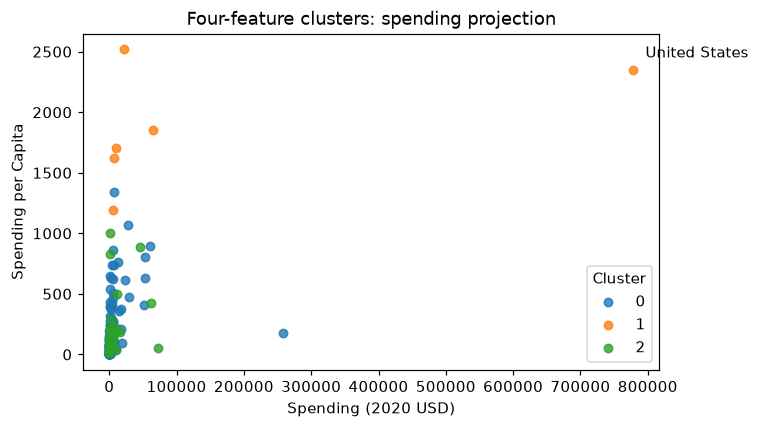

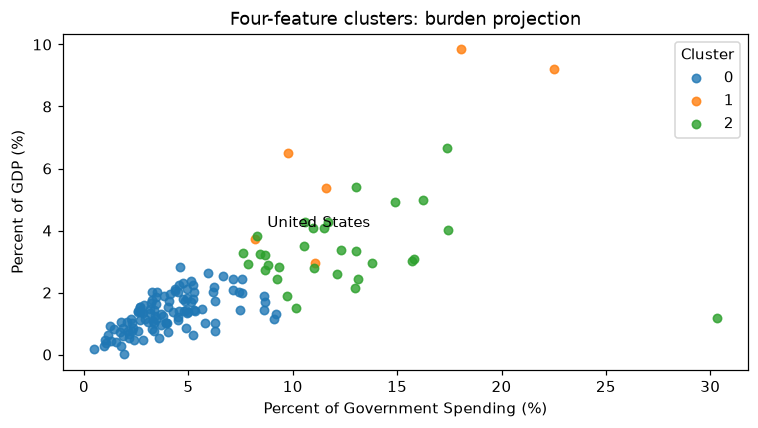

Spending versus all-feature membership:


all_cluster,0,1,2
spending_cluster,,,
0,85,0,26
1,25,0,5
2,0,1,0
3,1,5,0


Burden versus all-feature membership:


all_cluster,0,1,2
burden_cluster,,,
0,12,2,25
1,99,0,0
2,0,4,6


Countries in the US cluster: ['Israel', 'Kuwait', 'Oman', 'Saudi Arabia', 'Singapore', 'United States of America']


In [6]:
# Q2.4: fit all four normalized features.
plot_scree(all_X, 'All four military spending features', chosen_k=3)
all_model = fit_kmeans(all_X, 3)
military['all_cluster'] = all_model.labels_
report_clusters(military, features_p2, 'all_cluster')
print('Cluster means in original units:')
display(military.groupby('all_cluster')[features_p2].mean().round(3))
scatter_clusters(military, spending_features, 'all_cluster',
                 'Four-feature clusters: spending projection')
scatter_clusters(military, burden_features, 'all_cluster',
                 'Four-feature clusters: burden projection', percentages=True)
print('Spending versus all-feature membership:')
display(pd.crosstab(military['spending_cluster'], military['all_cluster']))
print('Burden versus all-feature membership:')
display(pd.crosstab(military['burden_cluster'], military['all_cluster']))
us_label = military.loc[military['Country'].eq('United States of America'),
                        'all_cluster'].iloc[0]
us_members = military.loc[military['all_cluster'].eq(us_label), 'Country'].tolist()
print('Countries in the US cluster:', us_members)
assert military.groupby('all_cluster').size().tolist() == [111, 6, 31]
assert set(us_members) == {'Israel', 'Kuwait', 'Oman', 'Saudi Arabia',
                           'Singapore', 'United States of America'}


**Q2.4:** k=3 is a reasonable descriptive choice; the scree curve does not have a sharp elbow. The clusters contain 111, 6, and 31 countries. Cluster 0 generally combines lower per-capita spending with lower burden. Cluster 1 includes Israel, Kuwait, Oman, Saudi Arabia, Singapore, and the United States, combining high per-capita spending and/or high burden. Cluster 2 generally has greater burden than cluster 0 but more modest per-capita spending than cluster 1. These descriptions summarize group averages, not rules satisfied by every country.

Compared with Q2.2, the US is no longer a singleton. Norway leaves the high-per-capita group when burden is included. Compared with Q2.3, high per-capita spending can distinguish countries that have similar budget/GDP burdens. The cross-tabs quantify these changes. Each scatterplot is a two-dimensional projection of the same model fitted on four features, so overlapping points in one projection may differ in the other features.

**Q2.5:** Yes: clustering distinguishes absolute spending, spending per person, and military expenditure relative to available resources. It highlights the US as an extreme total spender while showing that other countries bear higher relative burdens. The four-feature model reveals countries with similar combined spending profiles.

These are descriptive patterns, not explanations of why countries spend as they do or judgments about policy. Min-max scaling gives each feature the same range but does not remove skew: the US stretches the total-spending range and compresses differences among most other countries. Related features can also give overlapping aspects of spending extra influence. Results depend on feature selection, scaling, k, and initialization; fixed seeds and multiple initializations improve reproducibility but do not prove that the chosen partition is uniquely correct. Because inertia decreases as more clusters are added, an elbow requires interpretation. All conclusions here concern the complete 2020 observations.


### *Reflection on AI assistance


AI is a great productivity and debugging tool. I like spec-driven development, where I can send AI a clear prompt with detailed and clear verification/validation plan. Using this approach, AI could check the work thoroughly, and it can help gap the miscommunications written by humans.


For this homework specifically, AI helped me check and verify the entire problem: from importing libraries to implementing actual logic and summarizing the findings. AI did a great job on summarizing the findings I got. In my phase 1, some wordings might be unclear and too simplified, and AI did a great job helping me elaborating and answering the questions in a clearer way.


To sum up, AI is a good copilot when tackling problems and debugging, but humans are still an essential part in guiding it, verifying its output, and do the manual work.
